In [1]:
import pandas as pd
import os
import smarts_cerebellum.globals as gl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np

# DTI metrics
dti = pd.read_csv(os.path.join(gl.baseDir, 'DTI', 'WMPMII_DTI_flip.tsv'), sep = '\t')
dti = dti[dti.isPatient == 1] # just patients
dti = dti[dti.metric == 'FaMap']


# cerebellum GMV
cerebel = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_GM', 'summary_MNISymC_Nettekoven_2024_GM_mod.tsv'), sep = '\t')
cerebel = cerebel[cerebel.isPatient==1] # just patients

cerebel['hemisphere'] = cerebel.regionname.str[2]
cerebel['regionname_bilat'] = cerebel.regionname.str[:2]

cerebel_wide = cerebel.pivot(index = ['subj_id', 'Week', 'regionname_bilat'], columns = 'hemisphere', values = 'mean')
cerebel_wide['left_norm'] = cerebel_wide['L']/cerebel_wide['R']
cerebel_wide = cerebel_wide.reset_index()
cerebel = cerebel_wide.melt(
    id_vars = ['subj_id', 'Week', 'regionname_bilat'],
    value_vars = ['L', 'R', 'left_norm'],
    var_name = 'metric_cerebel', value_name = 'mean_cerebel'
)
cerebel = cerebel[cerebel.metric_cerebel == 'left_norm']
cerebel = cerebel.drop(columns = 'metric_cerebel')
cerebel = cerebel.rename(columns = {'mean_cerebel': 'left_norm'})

# behavioural metrics
behav = pd.read_csv(os.path.join(gl.baseDir, 'behavioural', 'summary_paretic.dat'), sep = '\t')
behav.rename(columns = {'subj_name': 'subj_id', 'week': 'Week'}, inplace = True)
behav['subj_id'] = behav['subj_id'].str.strip()
behav.loc[behav['Week']==1, 'Week'] = 0

/localscratch/tmp/ipykernel_57001/851076707.py:10: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  dti = pd.read_csv(os.path.join(gl.baseDir, 'DTI', 'WMPMII_DTI_flip.tsv'), sep = '\t')


Asymmetry index for FA = (FA_left - FA_right) / (FA_left + FA_right)

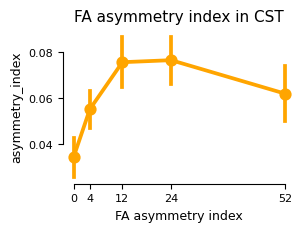

**t-test against 0 asymmetry index in CST at week 0: 
 t-value: 4.049557558103627 	 p-value: 0.00028087459887843916 

**t-test against 0 asymmetry index in CST at week 4: 
 t-value: 6.85465287663012 	 p-value: 5.096233190204944e-08 

**t-test against 0 asymmetry index in CST at week 12: 
 t-value: 6.9932852572070665 	 p-value: 5.359367546995319e-08 

**t-test against 0 asymmetry index in CST at week 24: 
 t-value: 7.517184079061162 	 p-value: 2.7585663637962996e-08 

**t-test against 0 asymmetry index in CST at week 52: 
 t-value: 5.130214303140528 	 p-value: 5.098797195120082e-05 



In [2]:
fig, ax = plt.subplots(figsize=(3,2))
dti_roi = dti[dti.regionname == 'CST_R']
sns.pointplot(x = 'Week', y = 'asymmetry_index', data = dti_roi, ax = ax, errorbar = 'se', native_scale = True, color = 'orange')

plt.xlabel("FA asymmetry index")
plt.title("FA asymmetry index in CST")
ax.set_xticks(gl.weeks)
sns.despine(trim = True)
plt.show()

# test significance against 0 for each time point
for week in gl.weeks:
    t_val, p_val = stats.ttest_1samp(dti_roi[dti_roi.Week == week]['asymmetry_index'], popmean = 0)
    print(f'**t-test against 0 asymmetry index in CST at week {week}: \n t-value: {t_val} \t p-value: {p_val} \n')


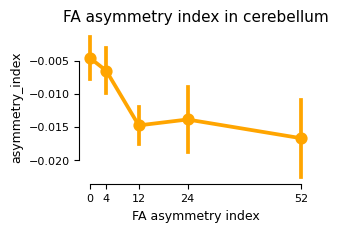

**t-test against 0 asymmetry index in cerebellum at week 0: 
 t-value: -1.4373563966323384 	 p-value: 0.15975685396234449 

**t-test against 0 asymmetry index in cerebellum at week 4: 
 t-value: -1.9399295124240568 	 p-value: 0.06025367540142692 

**t-test against 0 asymmetry index in cerebellum at week 12: 
 t-value: -5.344958947794675 	 p-value: 6.665320336747181e-06 

**t-test against 0 asymmetry index in cerebellum at week 24: 
 t-value: -2.8261021982366006 	 p-value: 0.008444809066947117 

**t-test against 0 asymmetry index in cerebellum at week 52: 
 t-value: -2.8812298449479523 	 p-value: 0.009232558040239421 



In [3]:
fig, ax = plt.subplots(figsize=(3,2))
dti_roi = dti[dti.regionname == 'cerebellum_L']
sns.pointplot(x = 'Week', y = 'asymmetry_index', data = dti_roi, ax = ax, errorbar = 'se', native_scale = True, color = 'orange')

plt.xlabel("FA asymmetry index")
plt.title("FA asymmetry index in cerebellum")
ax.set_xticks(gl.weeks)
sns.despine(trim = True)
plt.show()

# test significance against 0 for each time point
for week in gl.weeks:
    t_val, p_val = stats.ttest_1samp(dti_roi[dti_roi.Week == week]['asymmetry_index'], popmean = 0)
    print(f'**t-test against 0 asymmetry index in cerebellum at week {week}: \n t-value: {t_val} \t p-value: {p_val} \n')


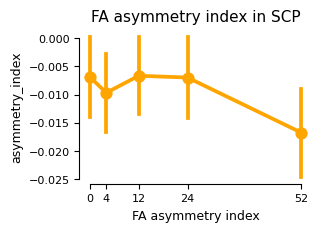

**t-test against 0 asymmetry index in SCP at week 0: 
 t-value: -0.9804864607995166 	 p-value: 0.33377176108234996 

**t-test against 0 asymmetry index in SCP at week 4: 
 t-value: -1.4119965544586994 	 p-value: 0.16653698740842637 

**t-test against 0 asymmetry index in SCP at week 12: 
 t-value: -0.9843118441095378 	 p-value: 0.3321243613138777 

**t-test against 0 asymmetry index in SCP at week 24: 
 t-value: -0.9696725628719015 	 p-value: 0.34022812882915265 

**t-test against 0 asymmetry index in SCP at week 52: 
 t-value: -2.1495013087205814 	 p-value: 0.04401381233964571 



In [4]:
fig, ax = plt.subplots(figsize=(3,2))
dti_roi = dti[dti.regionname == 'SCP_L']
sns.pointplot(x = 'Week', y = 'asymmetry_index', data = dti_roi, ax = ax, errorbar = 'se', native_scale = True, color = 'orange')

plt.xlabel("FA asymmetry index")
plt.title("FA asymmetry index in SCP")
ax.set_xticks(gl.weeks)
sns.despine(trim = True)
plt.show()

# test significance against 0 for each time point
for week in gl.weeks:
    t_val, p_val = stats.ttest_1samp(dti_roi[dti_roi.Week == week]['asymmetry_index'], popmean = 0)
    print(f'**t-test against 0 asymmetry index in SCP at week {week}: \n t-value: {t_val} \t p-value: {p_val} \n')


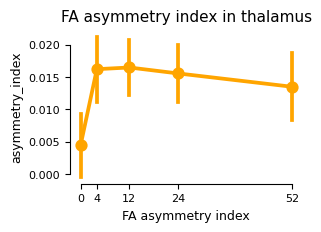

**t-test against 0 asymmetry index in thalamus at week 0: 
 t-value: 0.9113432766123863 	 p-value: 0.36853101714199066 

**t-test against 0 asymmetry index in thalamus at week 4: 
 t-value: 3.2283489089584854 	 p-value: 0.0026561318707625813 

**t-test against 0 asymmetry index in thalamus at week 12: 
 t-value: 3.8159172667303642 	 p-value: 0.0005655614836806481 

**t-test against 0 asymmetry index in thalamus at week 24: 
 t-value: 3.5099413750152846 	 p-value: 0.0014851122770362516 

**t-test against 0 asymmetry index in thalamus at week 52: 
 t-value: 2.583174598373956 	 p-value: 0.017761048423417903 



In [5]:
fig, ax = plt.subplots(figsize=(3,2))
dti_roi = dti[dti.regionname == 'Thal_R']
sns.pointplot(x = 'Week', y = 'asymmetry_index', data = dti_roi, ax = ax, errorbar = 'se', native_scale = True, color = 'orange')

plt.xlabel("FA asymmetry index")
plt.title("FA asymmetry index in thalamus")
ax.set_xticks(gl.weeks)
sns.despine(trim = True)
plt.show()

# test significance against 0 for each time point
for week in gl.weeks:
    t_val, p_val = stats.ttest_1samp(dti_roi[dti_roi.Week == week]['asymmetry_index'], popmean = 0)
    print(f'**t-test against 0 asymmetry index in thalamus at week {week}: \n t-value: {t_val} \t p-value: {p_val} \n')


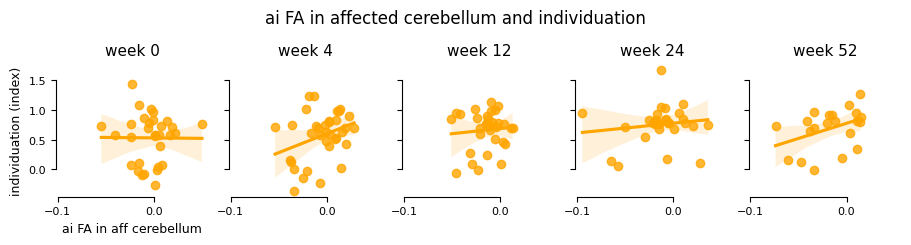

**Pearson R and p-value for ai FA in affected cerebellum and individuation** 

week 0: r = -0.007301878448456664, p-value = 0.9689024416579083
week 4: r = 0.3254919998662336, p-value = 0.05638783973082124
week 12: r = 0.08852132672628504, p-value = 0.6299643578581896
week 24: r = 0.1378326612926689, p-value = 0.4758357093421618
week 52: r = 0.4002121609875248, p-value = 0.0722247262632909


In [6]:
# affected: ipsilesional cerebellum, paretic hand
fig, axs = plt.subplots(1, 5, figsize = (9,2), sharey = True, sharex = True, constrained_layout = True)
for i, week in enumerate(gl.weeks):
    behav_plot = behav[behav.Week == week]
    dti_plot = dti[(dti.Week == week) & (dti.regionname == 'cerebellum_L')]
    behav_dti_plot = pd.merge(dti_plot, behav_plot, on = ['subj_id', 'Week'], suffixes = ('_dti', '_behav'))

    ax = axs[i]
    sns.regplot(x = 'asymmetry_index', y = 'indiv_norm', data = behav_dti_plot, ax = ax, color = 'orange')

    ax.set_ylabel('')
    ax.set_xlabel('')

    ax.set_title(f'week {week}')
    

axs[0].set_ylabel("individuation (index)")
axs[0].set_xlabel(f"ai FA in aff cerebellum")
fig.suptitle(f"ai FA in affected cerebellum and individuation", y = 1.15)

sns.despine(trim = True)
plt.show()


print("**Pearson R and p-value for ai FA in affected cerebellum and individuation** \n")
for week in gl.weeks:
    behav_plot = behav[behav.Week == week]
    dti_plot = dti[(dti.Week == week) & (dti.regionname == 'cerebellum_L')]
    behav_dti_plot = pd.merge(dti_plot, behav_plot, on = ['subj_id', 'Week'], suffixes = ('_dti', '_behav'))

    r_stat, p_stat = stats.pearsonr(behav_dti_plot['asymmetry_index'], behav_dti_plot['indiv_norm'])
    print(f'week {week}: r = {r_stat}, p-value = {p_stat}')


/localscratch/tmp/ipykernel_57001/2921453812.py:2: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  dti = pd.read_csv(os.path.join(gl.baseDir, 'DTI', 'WMPMII_DTI_flip.tsv'), sep = '\t')


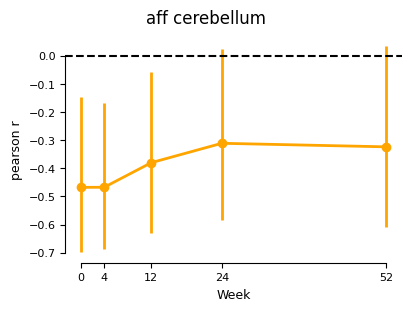

,Week,roi,r_stat,p_val,n,z,se,lo,hi
0,0,CST_R,-0.467716,0.006057,33,-0.507143,0.182574,-0.698819,-0.148198
1,4,CST_R,-0.467443,0.003534,37,-0.506794,0.171499,-0.687358,-0.169019
2,12,CST_R,-0.380090,0.022217,36,-0.400165,0.174078,-0.629965,-0.058905


In [7]:
# correlations for ai FA in cerebellum W0 (or W4) and indiv
dti = pd.read_csv(os.path.join(gl.baseDir, 'DTI', 'WMPMII_DTI_flip.tsv'), sep = '\t')
dti = dti[dti.isPatient == 1] # just patients
dti = dti[dti.metric == 'FaMap']
dti_week = [0, 4]
dti = dti[(dti.regionname == 'CST_R') & (dti.Week.isin(dti_week))] # W0 FA as measure of integrity of affected CS
dti = dti.sort_values('Week').drop_duplicates(['subj_id', 'side'], keep = 'first').reset_index(drop = True) # W0 (or W4 for those wihtout W0)
behav_dti = behav.merge(dti, on = 'subj_id', suffixes = ('_behav', '_dti'))

rows = []
for week in gl.weeks:

    corr_df = behav_dti[(behav_dti.Week_behav == week) & (behav_dti.regionname == 'CST_R')]
    r_stat, p_val = stats.pearsonr(corr_df['asymmetry_index'],corr_df['indiv_norm'])

    n = len(corr_df.subj_id.unique())
    z, se = np.arctanh(r_stat), 1/np.sqrt(n - 3)
    lo, hi = np.tanh([z - 1.96*se, z + 1.96*se])
    rows.append({'Week': week, 'roi': 'CST_R', 'r_stat': r_stat, 'p_val': p_val, 'n': n, 'z': z, 'se': se, 'lo': lo, 'hi': hi})
        
r_df = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize = (4,3), constrained_layout = True)
ax.errorbar(x = r_df['Week'], y = r_df['r_stat'], yerr = [r_df['r_stat'] - r_df['lo'], r_df['hi'] - r_df['r_stat']], 
            marker = 'o', linestyle = '-', linewidth = 2, color = 'orange')

ax.set_xticks(gl.weeks)
ax.set_xlabel('Week')
ax.set_ylabel('pearson r')
plt.axhline(y = 0, linestyle = '--', color = 'k', linewidth = '1.5')
fig.suptitle('aff cerebellum')
sns.despine(trim = True)
plt.show()

display(r_df[r_df.p_val < 0.05])

We can look at FA values in particular rois (using our FaMap images) next, correlate them with behaviour